## Visualizzazioni V0

**Rigenerazione:** i dati restano in `results/brt/<metrica>.npz`. Eseguire il notebook dall’inizio con Restart Kernel / Run All. Le anteprime precedenti sono state svuotate per evitare figure obsolete. Tutte le colorbar mostrano due decimali; i parametri fissi sono da specificare nelle caption.

Input: /home/alessio-grisorio/TESI/hj_reachability/results/brt/euclidean.npz
Campo: V0; v_E=6, v_H=6, delta_E=0 rad


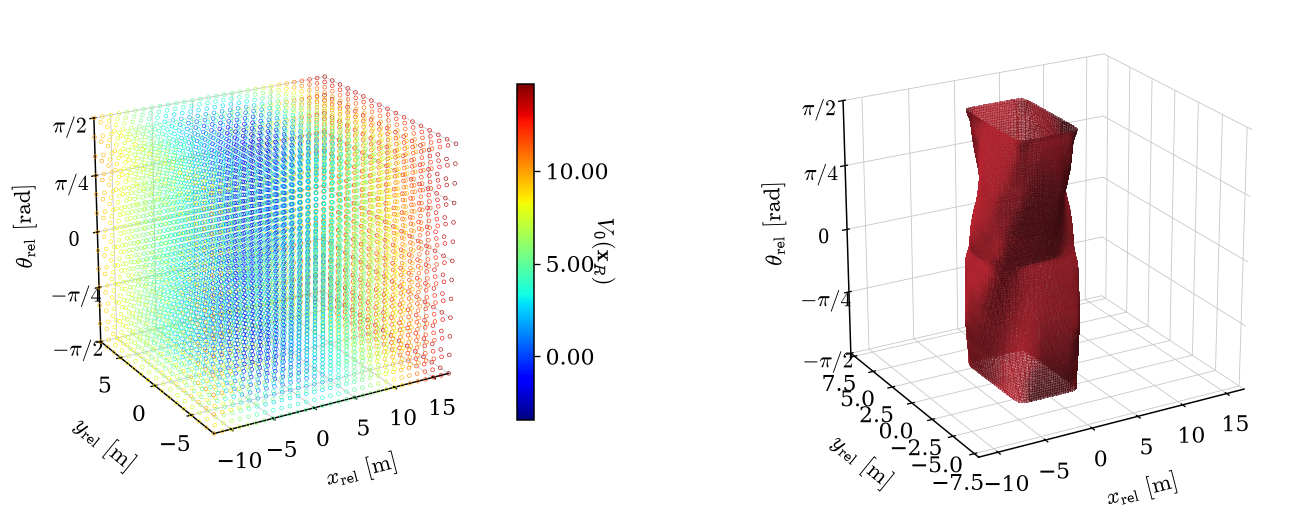

In [1]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from plot_utils import set_style, export_figure, finish_figure

set_style()


# Individua la radice del repository.
ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "scripts" / "plot_terminal_value.py").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Apri il notebook all'interno del repository hj_reachability."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts import plot_terminal_value as terminal
from scripts import compare_terminal_values as comparison


# ---------------- Configurazione ----------------

METRIC = "euclidean"
DATA_DIRECTORY = ROOT / "results" / "brt"

V_E = 6.0
V_H = 6.0
DELTA_E = 0.0

X_LIMITS = None
Y_LIMITS = None
THETA_LIMITS = (-np.pi / 2, np.pi / 2)

FIGURE_SIZE = (12.0, 5.0)
ELEVATION = 22
AZIMUTH = -120

COLORMAP = "jet"
COLOR_LIMITS = None
SCATTER_STRIDE = (1, 1, 2)
SCATTER_SIZE = 5.0

SURFACE_COLOR = plt.get_cmap("RdBu_r")(0.88)
SURFACE_ALPHA = 0.5
SURFACE_REFINEMENT = 4
SMOOTHING_SIGMA = 0.8

# ------------------------------------------------


terminal.KEY = "V0"
terminal.DATA_DIRECTORY = DATA_DIRECTORY
terminal.INPUT_FILE = None

terminal.V_E = V_E
terminal.V_H = V_H
terminal.DELTA_E = DELTA_E

terminal.X_LIMITS = X_LIMITS
terminal.Y_LIMITS = Y_LIMITS
terminal.THETA_LIMITS = THETA_LIMITS
terminal.ELEVATION = ELEVATION
terminal.AZIMUTH = AZIMUTH

comparison.V_E_3D = V_E
comparison.V_H = V_H
comparison.DELTA_E = DELTA_E
comparison.SURFACE_ALPHA = SURFACE_ALPHA
comparison.SURFACE_REFINEMENT = SURFACE_REFINEMENT
comparison.SMOOTHING_SIGMA = SMOOTHING_SIGMA


# Carica V0 e interpola nelle coordinate fissate.
axes, values, field_label = terminal.load_slice(METRIC)
extended_axes, extended_values, limits = terminal.prepare_domain(
    axes, values
)

interpolator = terminal.RegularGridInterpolator(
    extended_axes,
    extended_values,
    bounds_error=True,
)

scatter_axes = [
    axis[
        (axis >= lower - 1e-7)
        & (axis <= upper + 1e-7)
    ][::stride]
    for axis, (lower, upper), stride in zip(
        axes, limits, SCATTER_STRIDE
    )
]

if any(len(axis) == 0 for axis in scatter_axes):
    raise ValueError("Nessun nodo scatter nei limiti selezionati.")

points = np.stack(
    np.meshgrid(*scatter_axes, indexing="ij"),
    axis=-1,
).reshape(-1, 3)

point_values = interpolator(points)

vmin, vmax = (
    COLOR_LIMITS
    if COLOR_LIMITS is not None
    else (float(values.min()), float(values.max()))
)

if not vmin < vmax:
    raise ValueError("Seleziona limiti colore con minimo < massimo.")

norm = colors.Normalize(vmin=vmin, vmax=vmax)
cmap = plt.get_cmap(COLORMAP)


# Figura nello stile del grafico 3D originale.


fig_v0 = plt.figure(figsize=FIGURE_SIZE, layout="none")
fig_v0.subplots_adjust(
    left=0.12, right=0.97, bottom=0.13, top=0.98, wspace=0.55,
)

ax_scatter = fig_v0.add_subplot(121, projection="3d")
ax_surface = fig_v0.add_subplot(122, projection="3d")

for ax in (ax_scatter, ax_surface):
    terminal.configure_axis(ax, limits)
    ax.tick_params(labelsize=plt.rcParams["xtick.labelsize"])

ax_scatter.scatter(
    *points.T,
    s=SCATTER_SIZE,
    facecolors="none",
    edgecolors=cmap(norm(point_values)),
    linewidths=0.35,
    depthshade=False,
    rasterized=True,
)

colorbar = fig_v0.colorbar(
    cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax_scatter,
    shrink=0.68,
    pad=0.08,
    fraction=0.035,
)

colorbar.set_label(rf"${field_label}$")
colorbar.ax.tick_params(labelsize=plt.rcParams["ytick.labelsize"])

# La routine dei confronti riceve una fetta già fissata:
# gli ultimi tre assi sono quindi singleton.
surface_axes = [
    *axes,
    np.array([V_H]),
    np.array([DELTA_E]),
    np.array([V_E]),
]

comparison.plot_surface(
    ax_surface,
    surface_axes,
    values[..., None, None, None],
    SURFACE_COLOR,
    METRIC,
    limits,
)
#fig_v0.suptitle(
    #rf"$v_E={V_E:g}\,\mathrm{{m/s}}"
    #rf"\qquad v_H={V_H:g}\,\mathrm{{m/s}}"
    #rf"\qquad \delta_E={DELTA_E:g}\,\mathrm{{rad}}$",
    #"$v_E\,\mathrm{{invariant}}"
    #"\qquad v_H\,\mathrm{{invariant}}"
    #"\qquad \delta_E\,\mathrm{{invariant}}$",
    #y=1.0,
#)
finish_figure(plt.gcf())
plt.show()

In [2]:
# Salvataggio
export_figure(
    fig_v0,
    nome="euclidean_v0",
    cartella=METRIC,
    formati=("pdf", "eps"),
    sovrascrivi=True,
)

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_v0.pdf


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as uni

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_v0.eps


[PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_v0.pdf'),
 PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_v0.eps')]

## V0 slices

In [3]:
from fractions import Fraction

from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter

from scripts.plot_terminal_slices import bracket


# ---------------- Configurazione ----------------

THETA_VALUES = (-np.pi / 4, 0.0, np.pi / 4)

SLICE_FIGURE_SIZE = (12.0, 3.8)
SLICE_REFINEMENT = 6
SLICE_SMOOTHING_SIGMA = 0.8
SLICE_COLORMAP = "RdBu_r"

SLICE_X_LIMITS = None
SLICE_Y_LIMITS = None

ZERO_COLOR = "black"
ZERO_LINEWIDTH = 1.0

EGO_LENGTH = 4.68
EGO_WIDTH = 2.20
EGO_FACE = "lightcyan"
EGO_EDGE = "#263746"

# ------------------------------------------------


def theta_label(angle):
    fraction = Fraction(float(angle / np.pi)).limit_denominator(24)

    if not np.isclose(
        float(fraction) * np.pi, angle, rtol=0, atol=1e-9
    ):
        return f"{angle:.3g}"

    numerator = fraction.numerator
    denominator = fraction.denominator

    if numerator == 0:
        return "0"

    sign = "-" if numerator < 0 else ""
    top = (
        r"\pi"
        if abs(numerator) == 1
        else rf"{abs(numerator)}\pi"
    )

    if denominator == 1:
        return sign + top

    return rf"{sign}\frac{{{top}}}{{{denominator}}}"


def prepare_xy_grid(x, y, refinement, x_limits=None, y_limits=None):
    if int(refinement) != refinement or refinement < 1:
        raise ValueError("Il raffinamento deve essere un intero positivo.")

    limits_xy = [
        x_limits if x_limits is not None else (x[0], x[-1]),
        y_limits if y_limits is not None else (y[0], y[-1]),
    ]

    for axis, (lower, upper) in zip((x, y), limits_xy):
        if (
            lower >= upper
            or lower < axis[0]
            or upper > axis[-1]
        ):
            raise ValueError("Limiti spaziali fuori dal dominio.")

    fine_axes = [
        np.linspace(
            axis[0],
            axis[-1],
            (len(axis) - 1) * int(refinement) + 1,
        )
        for axis in (x, y)
    ]

    fine_points = np.stack(
        np.meshgrid(*fine_axes, indexing="ij"),
        axis=-1,
    )

    crop_axes = [
        np.unique(np.r_[
            lower,
            axis[(axis > lower) & (axis < upper)],
            upper,
        ])
        for axis, (lower, upper) in zip(fine_axes, limits_xy)
    ]

    crop_points = np.stack(
        np.meshgrid(*crop_axes, indexing="ij"),
        axis=-1,
    )

    return (
        limits_xy,
        fine_axes,
        fine_points,
        crop_axes,
        crop_points,
    )


def prepare_xy_slice(
    section,
    x,
    y,
    fine_axes,
    fine_points,
    crop_points,
    smoothing,
):
    if smoothing < 0:
        raise ValueError("Lo smoothing deve essere >= 0.")

    fine = RegularGridInterpolator(
        (x, y), section
    )(fine_points)

    if smoothing:
        fine = gaussian_filter(
            fine,
            sigma=smoothing,
            mode="nearest",
        )

    plotted = RegularGridInterpolator(
        tuple(fine_axes), fine
    )(crop_points)

    if not np.isfinite(plotted).all():
        raise ValueError("La fetta contiene NaN o infiniti.")

    return plotted


def common_normalization(sections):
    lower = min(float(section.min()) for section in sections)
    upper = max(float(section.max()) for section in sections)

    if lower >= upper:
        raise ValueError("Colorbar degenere.")

    normalization = (
        TwoSlopeNorm(vmin=lower, vcenter=0, vmax=upper)
        if lower < 0 < upper
        else Normalize(vmin=lower, vmax=upper)
    )

    return lower, upper, normalization


if len(THETA_VALUES) != 3:
    raise ValueError("Seleziona esattamente tre angoli.")

# axes e values provengono dalla prima cella del grafico 3D di V0.
x_slice, y_slice, theta_slice = axes

(
    xy_limits,
    fine_axes_slice,
    fine_points_slice,
    crop_axes_slice,
    crop_points_slice,
) = prepare_xy_grid(
    x_slice,
    y_slice,
    SLICE_REFINEMENT,
    SLICE_X_LIMITS,
    SLICE_Y_LIMITS,
)

xr, yr = crop_axes_slice
v0_slices = []

for angle in THETA_VALUES:
    lo, hi, weight = bracket(
        theta_slice,
        angle,
        "theta_rel",
        periodic=True,
    )

    section = (
        (1 - weight) * values[:, :, lo]
        + weight * values[:, :, hi]
    )

    v0_slices.append(
        prepare_xy_slice(
            section,
            x_slice,
            y_slice,
            fine_axes_slice,
            fine_points_slice,
            crop_points_slice,
            SLICE_SMOOTHING_SIGMA,
        )
    )

vmin, vmax, slice_norm = common_normalization(v0_slices)

In [4]:
def make_speed_mosaic(field_key="BRT"):
    if field_key != "BRT":
        raise ValueError("Questa funzione è dedicata al mosaico BRT.")

    if len(V_E_VALUES) != 3 or len(V_H_VALUES) != 3:
        raise ValueError("Seleziona tre velocità ego e tre velocità human.")

    names = (
        "x_rel", "y_rel", "theta_rel",
        "v_H", "delta_E", "v_E",
    )

    rendered = {}

    with np.load(
        DATA_DIRECTORY / f"{METRIC}.npz",
        allow_pickle=False,
    ) as data:
        grid_axes = [
            np.asarray(data[name], dtype=float)
            for name in names
        ]

        if "state_names" in data:
            if tuple(data["state_names"].tolist()) != names:
                raise ValueError("Ordine degli stati incompatibile.")

        for name, axis in zip(names, grid_axes):
            if (
                axis.ndim != 1
                or not len(axis)
                or not np.isfinite(axis).all()
                or not np.all(np.diff(axis) > 0)
            ):
                raise ValueError(f"Asse non valido: {name}")

        target_time = float(data["target_time"])
        x, y = grid_axes[:2]

        (
            mosaic_limits,
            fine_axes,
            fine_points,
            crop_axes,
            crop_points,
        ) = prepare_xy_grid(
            x,
            y,
            MOSAIC_REFINEMENT,
            MOSAIC_X_LIMITS,
            MOSAIC_Y_LIMITS,
        )

        for key in ("BRT", "V0"):
            field = data[key]

            if field.shape != tuple(len(axis) for axis in grid_axes):
                raise ValueError(f"Forma incompatibile: {key}")

            rendered[key] = []

            for vh in V_H_VALUES:
                for ve in V_E_VALUES:
                    section = field

                    for dimension, value in (
                        (5, ve),
                        (4, DELTA_MOSAIC),
                        (3, vh),
                        (2, THETA_MOSAIC),
                    ):
                        lo, hi, weight = bracket(
                            grid_axes[dimension],
                            value,
                            names[dimension],
                            periodic=(dimension == 2),
                        )

                        section = (
                            (1 - weight)
                            * np.take(section, lo, axis=dimension)
                            + weight
                            * np.take(section, hi, axis=dimension)
                        )

                    rendered[key].append(
                        prepare_xy_slice(
                            section,
                            x,
                            y,
                            fine_axes,
                            fine_points,
                            crop_points,
                            MOSAIC_SMOOTHING,
                        )
                    )

            del field, section

    lower, upper, normalization = common_normalization(
        rendered["BRT"]
    )

    label = rf"V({target_time:g},\mathbf{{x}}_R)"

    set_style()

    fig = plt.figure(
        figsize=MOSAIC_SIZE,
        layout="constrained",
    )

    grid = fig.add_gridspec(
        4, 4,
        width_ratios=(1, 1, 1, 0.045),
        height_ratios=(0.20, 1, 1, 1),
    )

    header = fig.add_subplot(grid[0, :])
    header.set_axis_off()

    header.legend(
        handles=[
            Patch(
                facecolor=EGO_FACE,
                edgecolor=EGO_EDGE,
                linewidth=1.4,
                linestyle="--",
                label="Ego vehicle",
            ),
            Line2D(
                [], [],
                color=ZERO_COLOR,
                linewidth=ZERO_LINEWIDTH,
                label=rf"${label}=0$",
            ),
            Line2D(
                [], [],
                color="#287a32",
                linewidth=1.4,
                linestyle="--",
                label=r"$V_0(\mathbf{x}_R)=0$",
            ),
            
        ],
        loc="center",
        ncol=4,
        frameon=False,
        handlelength=2.5,
        columnspacing=1.3,
    )

    panels = []

    for index, (section, initial) in enumerate(
        zip(rendered["BRT"], rendered["V0"])
    ):
        row, column = divmod(index, 3)

        ax = fig.add_subplot(
            grid[row + 1, column],
            sharex=panels[0] if panels else None,
            sharey=panels[0] if panels else None,
        )
        panels.append(ax)

        image = ax.pcolormesh(
            *crop_axes,
            section.T,
            shading="gouraud",
            cmap=MOSAIC_COLORMAP,
            norm=normalization,
            rasterized=True,
        )

        if section.min() < 0 < section.max():
            ax.contour(
                *crop_axes,
                section.T,
                levels=[0],
                colors=ZERO_COLOR,
                linewidths=ZERO_LINEWIDTH,
            )

        if initial.min() < 0 < initial.max():
            ax.contour(
                *crop_axes,
                initial.T,
                levels=[0],
                colors="#287a32",
                linewidths=1.4,
                linestyles="--",
                zorder=4,
            )

        ax.add_patch(Rectangle(
            (-EGO_LENGTH / 2, -EGO_WIDTH / 2),
            EGO_LENGTH,
            EGO_WIDTH,
            facecolor=EGO_FACE,
            edgecolor=EGO_EDGE,
            linewidth=1.4,
            linestyle="--",
            zorder=5,
        ))

        ax.set_xlim(mosaic_limits[0])
        ax.set_ylim(mosaic_limits[1])
        ax.set_aspect("equal", adjustable="box")

        ax.tick_params(
            direction="out",
            length=3,
            labelbottom=(row == 2),
            labelleft=(column == 0),
        )

        if row == 2:
            ax.set_xlabel(r"$x_{\mathrm{rel}}\ [\mathrm{m}]$")

        if column == 0:
            ax.set_ylabel(
                rf"$v_H={V_H_VALUES[row]:g}\,\mathrm{{m/s}}$"
                "\n"
                r"$y_{\mathrm{rel}}\ [\mathrm{m}]$"
            )

        if row == 0:
            ax.set_title(
                rf"$v_E={V_E_VALUES[column]:g}\,\mathrm{{m/s}}$",
                pad=10,
            )

    cax = fig.add_subplot(grid[1:, 3])
    bar = fig.colorbar(image, cax=cax)

    ticks = (
        np.r_[
            np.linspace(lower, 0, 5),
            np.linspace(0, upper, 5)[1:],
        ]
        if lower < 0 < upper
        else np.linspace(lower, upper, 7)
    )

    bar.set_ticks(ticks)
    bar.set_ticklabels([f"{value:.2f}" for value in ticks])
    bar.set_label(rf"${label}$", labelpad=9)

    return fig

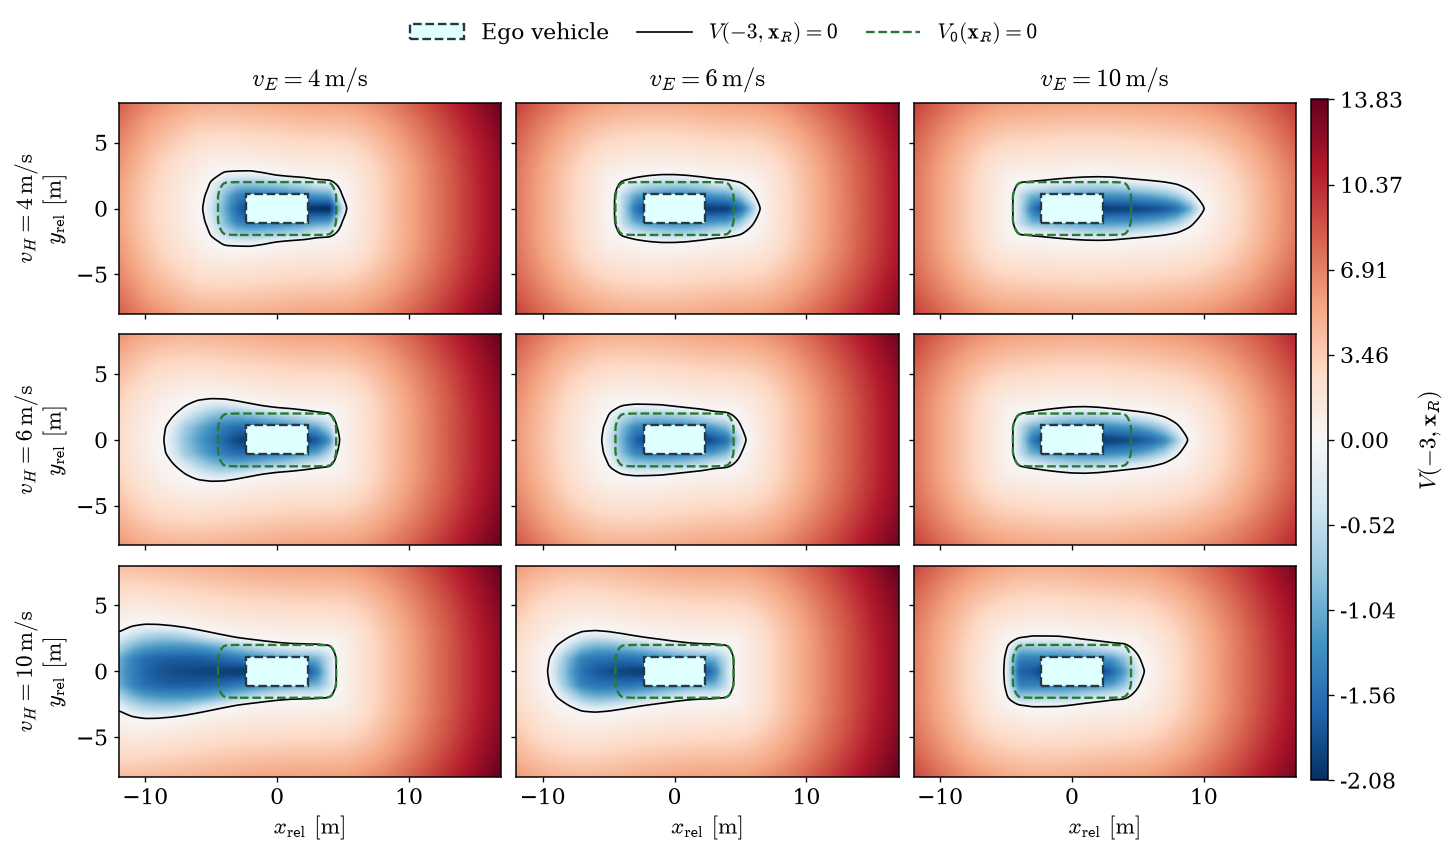

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt_slices.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very l

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt_slices.eps


[PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt_slices.pdf'),
 PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt_slices.eps')]

In [5]:
METRIC = "euclidean"
DATA_DIRECTORY = ROOT / "results" / "brt"

# Colonne: velocità ego. Righe: velocità human.
V_E_VALUES = (4.0, 6.0, 10.0)
V_H_VALUES = (4.0, 6.0, 10.0)

THETA_MOSAIC = 0.0
DELTA_MOSAIC = 0.0

MOSAIC_SIZE = (12.0, 7.0)
MOSAIC_X_LIMITS = None
MOSAIC_Y_LIMITS = None

MOSAIC_REFINEMENT = 6
MOSAIC_SMOOTHING = 0.8
MOSAIC_COLORMAP = "RdBu_r"

fig_brt_slices = make_speed_mosaic("BRT")
finish_figure(plt.gcf())
plt.show()

export_figure(
    fig_brt_slices,
    nome="euclidean_brt_slices",
    cartella=METRIC,
    formati=("pdf", "eps"),
    sovrascrivi=True,
)

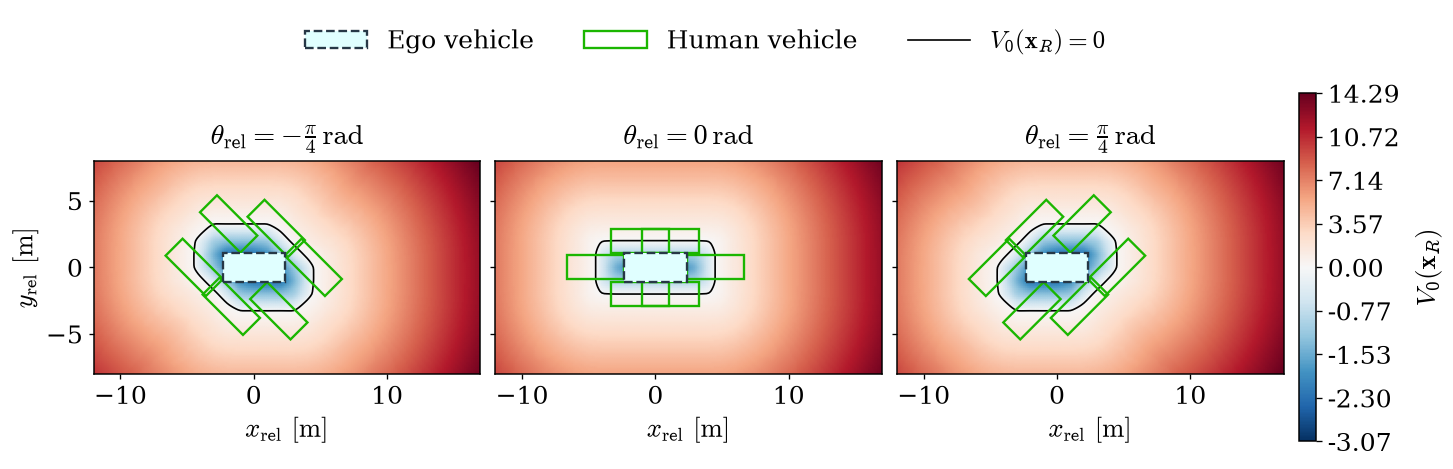

In [6]:
from matplotlib.transforms import Affine2D

SLICE_FIGURE_SIZE = (12.0, 3.8)

N_HUMAN = 6
HUMAN_ANGLE_OFFSET = 0.0  # Radianti: ruota la disposizione attorno a Ego.

HUMAN_LENGTH = 4.28
HUMAN_WIDTH = 1.80
HUMAN_COLOR = "#1BB600"
HUMAN_LINEWIDTH = 1.4

set_style(font_size=16)


def sample_contour_by_angle(paths, count, offset=0.0):
    """Interseca il bordo zero con raggi equispaziati attorno all'origine."""
    if count <= 0:
        return np.empty((0, 2))

    starts, ends = [], []

    for path in paths:
        path = np.asarray(path)

        if len(path) < 2:
            continue

        p0, p1 = path[:-1], path[1:]
        valid = (
            np.isfinite(p0).all(axis=1)
            & np.isfinite(p1).all(axis=1)
            & (np.linalg.norm(p1 - p0, axis=1) > 0)
        )

        starts.append(p0[valid])
        ends.append(p1[valid])

    if not starts:
        return np.empty((0, 2))

    starts = np.concatenate(starts)
    ends = np.concatenate(ends)
    segments = ends - starts

    centers = []
    angles = offset + np.linspace(0, 2 * np.pi, count, endpoint=False)

    for angle in angles:
        direction = np.array([np.cos(angle), np.sin(angle)])

        denominator = (
            direction[0] * segments[:, 1]
            - direction[1] * segments[:, 0]
        )

        valid = np.abs(denominator) > 1e-12

        p = starts[valid]
        s = segments[valid]
        denominator = denominator[valid]

        distance = (
            p[:, 0] * s[:, 1] - p[:, 1] * s[:, 0]
        ) / denominator

        fraction = (
            p[:, 0] * direction[1] - p[:, 1] * direction[0]
        ) / denominator

        intersections = (
            (distance > 1e-9)
            & (fraction >= -1e-9)
            & (fraction <= 1 + 1e-9)
        )

        if np.any(intersections):
            # Prima intersezione incontrata partendo da Ego.
            radius = distance[intersections].min()
            centers.append(radius * direction)

    return np.asarray(centers).reshape(-1, 2)


fig_v0_slices = plt.figure(
    figsize=SLICE_FIGURE_SIZE,
    layout="constrained",
)

grid = fig_v0_slices.add_gridspec(
    2, 4,
    width_ratios=(1, 1, 1, 0.045),
    height_ratios=(0.18, 1),
)

header = fig_v0_slices.add_subplot(grid[0, :])
header.set_axis_off()

legend_handles = [
    Patch(
        facecolor=EGO_FACE,
        edgecolor=EGO_EDGE,
        linewidth=1.4,
        linestyle="--",
        label="Ego vehicle",
    ),
    Patch(
        facecolor="none",
        edgecolor=HUMAN_COLOR,
        linewidth=HUMAN_LINEWIDTH,
        label="Human vehicle",
    ),
    Line2D(
        [0], [0],
        color=ZERO_COLOR,
        linewidth=ZERO_LINEWIDTH,
        label=r"$V_0(\mathbf{x}_R)=0$",
    ),
]

header.legend(
    handles=legend_handles,
    loc="center",
    ncol=3,
    frameon=False,
    handlelength=2.5,
    columnspacing=2.0,
)

slice_panels = []

for column, (plotted, theta_value) in enumerate(
    zip(v0_slices, THETA_VALUES)
):
    ax = fig_v0_slices.add_subplot(
        grid[1, column],
        sharex=slice_panels[0] if slice_panels else None,
        sharey=slice_panels[0] if slice_panels else None,
    )
    slice_panels.append(ax)

    slice_image = ax.pcolormesh(
        xr, yr, plotted.T,
        shading="gouraud",
        cmap=SLICE_COLORMAP,
        norm=slice_norm,
        rasterized=True,
    )

    if plotted.min() < 0 < plotted.max():
        zero_contour = ax.contour(
            xr, yr, plotted.T,
            levels=[0],
            colors=ZERO_COLOR,
            linewidths=ZERO_LINEWIDTH,
        )

        centers = sample_contour_by_angle(
            zero_contour.allsegs[0],
            N_HUMAN,
            offset=HUMAN_ANGLE_OFFSET,
        )

        for x_h, y_h in centers:
            transform = (
                Affine2D()
                .rotate(float(theta_value))
                .translate(x_h, y_h)
                + ax.transData
            )

            ax.add_patch(Rectangle(
                (-HUMAN_LENGTH / 2, -HUMAN_WIDTH / 2),
                HUMAN_LENGTH,
                HUMAN_WIDTH,
                transform=transform,
                facecolor="none",
                edgecolor=HUMAN_COLOR,
                linewidth=HUMAN_LINEWIDTH,
                zorder=6,
            ))

    ax.add_patch(Rectangle(
        (-EGO_LENGTH / 2, -EGO_WIDTH / 2),
        EGO_LENGTH,
        EGO_WIDTH,
        facecolor=EGO_FACE,
        edgecolor=EGO_EDGE,
        linewidth=1.4,
        linestyle="--",
        zorder=7,
    ))

    ax.set_xlim(xy_limits[0])
    ax.set_ylim(xy_limits[1])
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel(r"$x_{\mathrm{rel}}\ [\mathrm{m}]$")
    ax.tick_params(
        direction="out",
        length=3,
        labelleft=(column == 0),
    )

    ax.set_title(
        rf"$\theta_{{\mathrm{{rel}}}}={theta_label(theta_value)}"
        rf"\,\mathrm{{rad}}$",
        pad=10,
    )

    if column == 0:
        ax.set_ylabel(r"$y_{\mathrm{rel}}\ [\mathrm{m}]$")

slice_cax = fig_v0_slices.add_subplot(grid[1, 3])

slice_bar = fig_v0_slices.colorbar(
    slice_image,
    cax=slice_cax,
)

if vmin < 0 < vmax:
    color_ticks = np.r_[
        np.linspace(vmin, 0.0, 5),
        np.linspace(0.0, vmax, 5)[1:],
    ]
else:
    color_ticks = np.linspace(vmin, vmax, 7)

slice_bar.set_ticks(color_ticks)
slice_bar.set_ticklabels(
    [f"{value:.2f}" for value in color_ticks]
)
slice_bar.set_label(r"$V_0(\mathbf{x}_R)$", labelpad=9)

finish_figure(plt.gcf())
plt.show()

In [7]:
export_figure(
    fig_v0_slices,
    nome=f"{METRIC}_v0_slices",
    cartella=METRIC,
    formati=("pdf", "eps"),
    sovrascrivi=True,
)

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_v0_slices.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very l

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_v0_slices.eps


[PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_v0_slices.pdf'),
 PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_v0_slices.eps')]

## Visualizzazioni BRT

Input: /home/alessio-grisorio/TESI/hj_reachability/results/brt/euclidean.npz
Campo: BRT; v_E=6, v_H=6, delta_E=0 rad


/home/alessio-grisorio/TESI/hj_reachability/scripts/compare_terminal_values.py:178: UserWarning: euclidean: superficie zero tagliata al bordo x_rel.
  warnings.warn(f"{label}: superficie zero tagliata al bordo {NAMES[dim]}.")
/home/alessio-grisorio/TESI/hj_reachability/scripts/compare_terminal_values.py:178: UserWarning: euclidean: superficie zero tagliata al bordo y_rel.
  warnings.warn(f"{label}: superficie zero tagliata al bordo {NAMES[dim]}.")


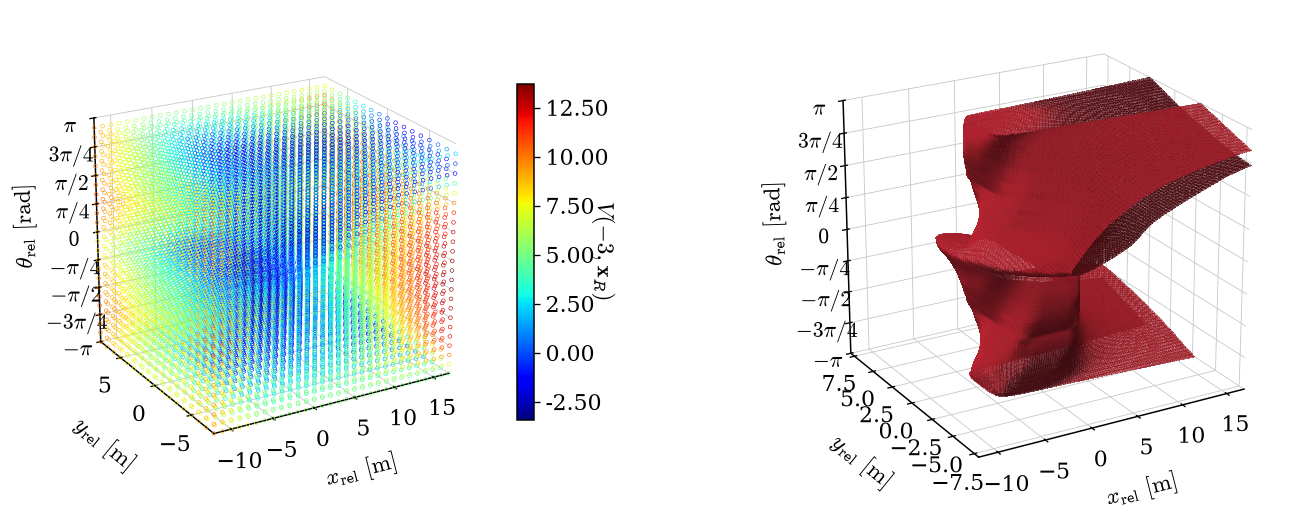

In [8]:
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from plot_utils import set_style, export_figure, finish_figure

set_style()


ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "scripts" / "plot_terminal_value.py").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Apri il notebook all'interno del repository hj_reachability."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts import plot_terminal_value as terminal
from scripts import compare_terminal_values as comparison


# ---------------- Configurazione ----------------

METRIC = "euclidean"
DATA_DIRECTORY = ROOT / "results" / "brt"

V_E = 6.0
V_H = 6.0
DELTA_E = 0.0

X_LIMITS = None
Y_LIMITS = None
THETA_LIMITS = (-np.pi / 2, np.pi / 2)

FIGURE_SIZE = (12.0, 5.0)
ELEVATION = 22
AZIMUTH = -120

COLORMAP = "jet"
COLOR_LIMITS = None
SCATTER_STRIDE = (1, 1, 2)
SCATTER_SIZE = 5.0

SURFACE_COLOR = plt.get_cmap("RdBu_r")(0.88)
SURFACE_ALPHA = 0.5
SURFACE_REFINEMENT = 4
SMOOTHING_SIGMA = 0.8

# ------------------------------------------------


terminal.KEY = "BRT"
terminal.DATA_DIRECTORY = DATA_DIRECTORY
terminal.INPUT_FILE = None

terminal.V_E = V_E
terminal.V_H = V_H
terminal.DELTA_E = DELTA_E

terminal.X_LIMITS = X_LIMITS
terminal.Y_LIMITS = Y_LIMITS
terminal.THETA_LIMITS = THETA_LIMITS
terminal.ELEVATION = ELEVATION
terminal.AZIMUTH = AZIMUTH

comparison.V_E_3D = V_E
comparison.V_H = V_H
comparison.DELTA_E = DELTA_E
comparison.SURFACE_ALPHA = SURFACE_ALPHA
comparison.SURFACE_REFINEMENT = SURFACE_REFINEMENT
comparison.SMOOTHING_SIGMA = SMOOTHING_SIGMA


# Carica il BRT e interpola nelle coordinate fissate.
axes_brt, values_brt, field_label_brt = terminal.load_slice(METRIC)

extended_axes_brt, extended_values_brt, limits_brt = (
    terminal.prepare_domain(axes_brt, values_brt)
)

interpolator_brt = terminal.RegularGridInterpolator(
    extended_axes_brt,
    extended_values_brt,
    bounds_error=True,
)

scatter_axes_brt = [
    axis[
        (axis >= lower - 1e-7)
        & (axis <= upper + 1e-7)
    ][::stride]
    for axis, (lower, upper), stride in zip(
        axes_brt, limits_brt, SCATTER_STRIDE
    )
]

if any(len(axis) == 0 for axis in scatter_axes_brt):
    raise ValueError("Nessun nodo scatter nei limiti selezionati.")

points_brt = np.stack(
    np.meshgrid(*scatter_axes_brt, indexing="ij"),
    axis=-1,
).reshape(-1, 3)

point_values_brt = interpolator_brt(points_brt)

vmin_brt, vmax_brt = (
    COLOR_LIMITS
    if COLOR_LIMITS is not None
    else (float(values_brt.min()), float(values_brt.max()))
)

if not vmin_brt < vmax_brt:
    raise ValueError("Seleziona limiti colore con minimo < massimo.")

norm_brt = colors.Normalize(vmin=vmin_brt, vmax=vmax_brt)
cmap_brt = plt.get_cmap(COLORMAP)




fig_brt = plt.figure(figsize=FIGURE_SIZE, layout="none")
fig_brt.subplots_adjust(
    left=0.12, right=0.97, bottom=0.13, top=0.98, wspace=0.55,
)

ax_scatter_brt = fig_brt.add_subplot(121, projection="3d")
ax_surface_brt = fig_brt.add_subplot(122, projection="3d")

for ax in (ax_scatter_brt, ax_surface_brt):
    terminal.configure_axis(ax, limits_brt)
    ax.tick_params(labelsize=plt.rcParams["xtick.labelsize"])

ax_scatter_brt.scatter(
    *points_brt.T,
    s=SCATTER_SIZE,
    facecolors="none",
    edgecolors=cmap_brt(norm_brt(point_values_brt)),
    linewidths=0.35,
    depthshade=False,
    rasterized=True,
)

colorbar_brt = fig_brt.colorbar(
    cm.ScalarMappable(norm=norm_brt, cmap=cmap_brt),
    ax=ax_scatter_brt,
    shrink=0.68,
    pad=0.08,
    fraction=0.035,
)

colorbar_brt.set_label(rf"${field_label_brt}$")
colorbar_brt.ax.tick_params(
    labelsize=plt.rcParams["ytick.labelsize"]
)

surface_axes_brt = [
    *axes_brt,
    np.array([V_H]),
    np.array([DELTA_E]),
    np.array([V_E]),
]

comparison.plot_surface(
    ax_surface_brt,
    surface_axes_brt,
    values_brt[..., None, None, None],
    SURFACE_COLOR,
    METRIC,
    limits_brt,
)

# Parametri fissi dichiarati nella caption.

finish_figure(plt.gcf())
plt.show()

In [9]:
# Salvataggio
export_figure(
    fig_brt,
    nome="euclidean_brt",
    cartella=METRIC,
    formati=("pdf", "eps"),
    sovrascrivi=True,
)

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt.pdf


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as uni

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt.eps


[PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt.pdf'),
 PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt.eps')]

## Slices BRT

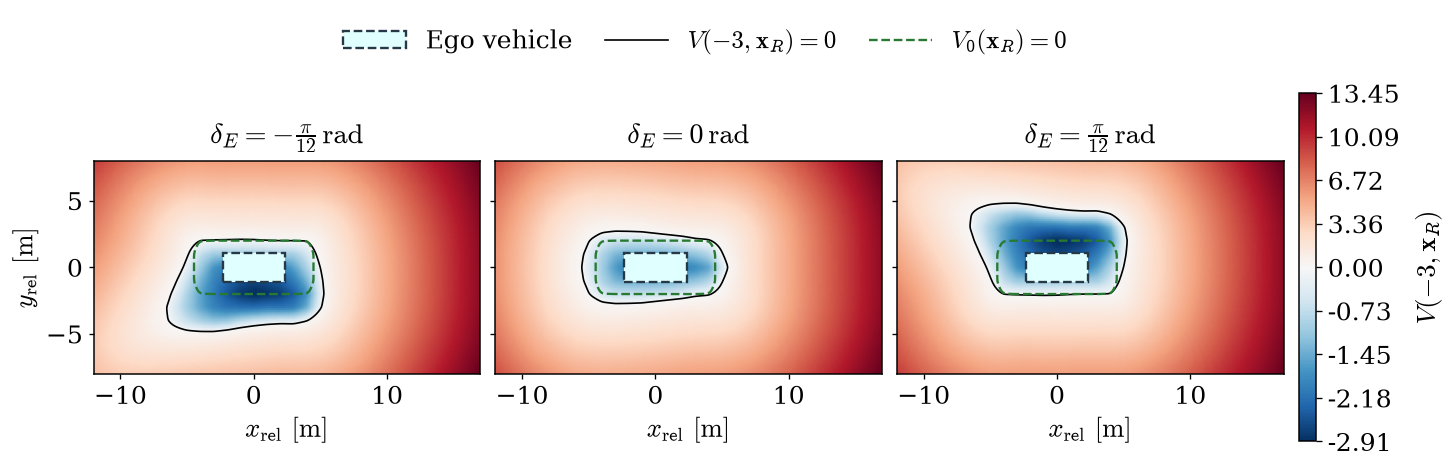

In [10]:
from fractions import Fraction

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter

from scripts.plot_terminal_slices import bracket
from plot_utils import set_style, export_figure, finish_figure


# ---------------- Configurazione ----------------

DELTA_VALUES = (-np.pi / 12, 0.0, np.pi / 12)

V_E_FIXED = 6.0
V_H_FIXED = 6.0
THETA_FIXED = 0.0

DELTA_X_LIMITS = None
DELTA_Y_LIMITS = None

DELTA_FIGURE_SIZE = (12.0, 3.8)
DELTA_REFINEMENT = 6
DELTA_SMOOTHING_SIGMA = 0.8

DELTA_COLORMAP = "RdBu_r"
DELTA_ZERO_COLOR = "black"
DELTA_ZERO_LINEWIDTH = 1.0

V0_CONTOUR_COLOR = "#287a32"
V0_CONTOUR_LINESTYLE = "--"
V0_CONTOUR_LINEWIDTH = 1.4

EGO_LENGTH = 4.68
EGO_WIDTH = 2.20
EGO_FACE = "lightcyan"
EGO_EDGE = "#263746"

# ------------------------------------------------


if len(DELTA_VALUES) != 3:
    raise ValueError("Seleziona esattamente tre valori di delta_E.")

if (
    int(DELTA_REFINEMENT) != DELTA_REFINEMENT
    or DELTA_REFINEMENT < 1
    or DELTA_SMOOTHING_SIGMA < 0
):
    raise ValueError("Raffinamento intero >= 1 e smoothing >= 0 richiesti.")

set_style(font_size=16)

state_names_delta = (
    "x_rel", "y_rel", "theta_rel", "v_H", "delta_E", "v_E"
)


def reduce_fixed_coordinates_delta(field, grid_axes):
    """Lascia libere soltanto x_rel, y_rel e delta_E."""
    result = field

    for dimension, fixed_value in (
        (5, V_E_FIXED),
        (3, V_H_FIXED),
        (2, THETA_FIXED),
    ):
        lo, hi, weight = bracket(
            grid_axes[dimension],
            fixed_value,
            state_names_delta[dimension],
            periodic=(dimension == 2),
        )

        result = (
            (1 - weight) * np.take(result, lo, axis=dimension)
            + weight * np.take(result, hi, axis=dimension)
        )

    return result


with np.load(
    ROOT / "results" / "brt" / f"{METRIC}.npz",
    allow_pickle=False,
) as data:
    axes_delta = [
        np.asarray(data[name], dtype=float)
        for name in state_names_delta
    ]

    if "state_names" in data:
        if tuple(data["state_names"].tolist()) != state_names_delta:
            raise ValueError("Ordine degli stati incompatibile.")

    target_time_delta = float(data["target_time"])

    expected_shape_delta = tuple(len(axis) for axis in axes_delta)

    # Carica e riduce un campo alla volta.
    reduced_fields_delta = {}

    for key in ("BRT", "V0"):
        field = data[key]

        if field.shape != expected_shape_delta:
            raise ValueError(f"Forma di {key} incompatibile con gli assi.")

        reduced_fields_delta[key] = reduce_fixed_coordinates_delta(
            field, axes_delta
        )

        del field


x_delta, y_delta = axes_delta[:2]
steering_axis_delta = axes_delta[4]

xy_limits_delta = [
    DELTA_X_LIMITS if DELTA_X_LIMITS is not None
    else (x_delta[0], x_delta[-1]),
    DELTA_Y_LIMITS if DELTA_Y_LIMITS is not None
    else (y_delta[0], y_delta[-1]),
]

for axis, (lower, upper) in zip(
    (x_delta, y_delta), xy_limits_delta
):
    if lower >= upper or lower < axis[0] or upper > axis[-1]:
        raise ValueError("Limiti spaziali fuori dal dominio della griglia.")

xf_delta = np.linspace(
    x_delta[0], x_delta[-1],
    (len(x_delta) - 1) * int(DELTA_REFINEMENT) + 1,
)

yf_delta = np.linspace(
    y_delta[0], y_delta[-1],
    (len(y_delta) - 1) * int(DELTA_REFINEMENT) + 1,
)

fine_points_delta = np.stack(
    np.meshgrid(xf_delta, yf_delta, indexing="ij"),
    axis=-1,
)

xr_delta = np.unique(np.r_[
    xy_limits_delta[0][0],
    xf_delta[
        (xf_delta > xy_limits_delta[0][0])
        & (xf_delta < xy_limits_delta[0][1])
    ],
    xy_limits_delta[0][1],
])

yr_delta = np.unique(np.r_[
    xy_limits_delta[1][0],
    yf_delta[
        (yf_delta > xy_limits_delta[1][0])
        & (yf_delta < xy_limits_delta[1][1])
    ],
    xy_limits_delta[1][1],
])

render_points_delta = np.stack(
    np.meshgrid(xr_delta, yr_delta, indexing="ij"),
    axis=-1,
)


def prepare_delta_slice(reduced_field, delta_value):
    lo, hi, weight = bracket(
        steering_axis_delta, delta_value, "delta_E"
    )

    original = (
        (1 - weight) * reduced_field[:, :, lo]
        + weight * reduced_field[:, :, hi]
    )

    fine = RegularGridInterpolator(
        (x_delta, y_delta), original
    )(fine_points_delta)

    if DELTA_SMOOTHING_SIGMA:
        fine = gaussian_filter(
            fine,
            sigma=DELTA_SMOOTHING_SIGMA,
            mode="nearest",
        )

    plotted = RegularGridInterpolator(
        (xf_delta, yf_delta), fine
    )(render_points_delta)

    if not np.isfinite(plotted).all():
        raise ValueError("La fetta contiene NaN o infiniti.")

    return plotted


brt_delta_slices = [
    prepare_delta_slice(reduced_fields_delta["BRT"], delta)
    for delta in DELTA_VALUES
]

v0_delta_slices = [
    prepare_delta_slice(reduced_fields_delta["V0"], delta)
    for delta in DELTA_VALUES
]

vmin_delta = min(float(s.min()) for s in brt_delta_slices)
vmax_delta = max(float(s.max()) for s in brt_delta_slices)

if not vmin_delta < vmax_delta:
    raise ValueError("Colorbar degenere: tutte le fette sono costanti.")

norm_delta = (
    TwoSlopeNorm(vmin=vmin_delta, vcenter=0.0, vmax=vmax_delta)
    if vmin_delta < 0 < vmax_delta
    else Normalize(vmin=vmin_delta, vmax=vmax_delta)
)


def angle_label_delta(angle):
    ratio = Fraction(float(angle / np.pi)).limit_denominator(24)

    if not np.isclose(float(ratio) * np.pi, angle, rtol=0, atol=1e-9):
        return rf"{angle:.3g}"

    numerator, denominator = ratio.numerator, ratio.denominator

    if numerator == 0:
        return "0"

    sign = "-" if numerator < 0 else ""
    magnitude = abs(numerator)
    top = r"\pi" if magnitude == 1 else rf"{magnitude}\pi"

    return (
        rf"{sign}{top}"
        if denominator == 1
        else rf"{sign}\frac{{{top}}}{{{denominator}}}"
    )


field_label_delta = rf"V({target_time_delta:g},\mathbf{{x}}_R)"

fig_brt_delta = plt.figure(
    figsize=DELTA_FIGURE_SIZE,
    layout="constrained",
)

grid_delta = fig_brt_delta.add_gridspec(
    2, 4,
    width_ratios=(1, 1, 1, 0.045),
    height_ratios=(0.18, 1),
)

header_delta = fig_brt_delta.add_subplot(grid_delta[0, :])
header_delta.set_axis_off()

fixed_parameters_delta = (
    rf"$v_E={V_E_FIXED:g}\,\mathrm{{m/s}}"
    rf"\qquad v_H={V_H_FIXED:g}\,\mathrm{{m/s}}"
    rf"\qquad \theta_{{\mathrm{{rel}}}}="
    rf"{angle_label_delta(THETA_FIXED)}\,\mathrm{{rad}}$"
)

header_delta.legend(
    handles=[
        Patch(
            facecolor=EGO_FACE,
            edgecolor=EGO_EDGE,
            linewidth=1.4,
            linestyle="--",
            label="Ego vehicle",
        ),
        Line2D(
            [0], [0],
            color=DELTA_ZERO_COLOR,
            linewidth=DELTA_ZERO_LINEWIDTH,
            label=rf"${field_label_delta}=0$",
        ),
        Line2D(
            [0], [0],
            color=V0_CONTOUR_COLOR,
            linewidth=V0_CONTOUR_LINEWIDTH,
            linestyle=V0_CONTOUR_LINESTYLE,
            label=r"$V_0(\mathbf{x}_R)=0$",
        ),
        
    ],
    loc="center",
    ncol=4,
    frameon=False,
    handlelength=2.5,
    columnspacing=1.3,
)

panels_delta = []

for column, (plotted, initial, delta_value) in enumerate(
    zip(brt_delta_slices, v0_delta_slices, DELTA_VALUES)
):
    ax = fig_brt_delta.add_subplot(
        grid_delta[1, column],
        sharex=panels_delta[0] if panels_delta else None,
        sharey=panels_delta[0] if panels_delta else None,
    )
    panels_delta.append(ax)

    image_delta = ax.pcolormesh(
        xr_delta, yr_delta, plotted.T,
        shading="gouraud",
        cmap=DELTA_COLORMAP,
        norm=norm_delta,
        rasterized=True,
    )

    if plotted.min() < 0 < plotted.max():
        ax.contour(
            xr_delta, yr_delta, plotted.T,
            levels=[0],
            colors=DELTA_ZERO_COLOR,
            linewidths=DELTA_ZERO_LINEWIDTH,
        )

    if initial.min() < 0 < initial.max():
        ax.contour(
            xr_delta, yr_delta, initial.T,
            levels=[0],
            colors=V0_CONTOUR_COLOR,
            linewidths=V0_CONTOUR_LINEWIDTH,
            linestyles=V0_CONTOUR_LINESTYLE,
            zorder=4,
        )

    ax.add_patch(Rectangle(
        (-EGO_LENGTH / 2, -EGO_WIDTH / 2),
        EGO_LENGTH,
        EGO_WIDTH,
        facecolor=EGO_FACE,
        edgecolor=EGO_EDGE,
        linewidth=1.4,
        linestyle="--",
        zorder=5,
    ))

    ax.set_xlim(xy_limits_delta[0])
    ax.set_ylim(xy_limits_delta[1])
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel(r"$x_{\mathrm{rel}}\ [\mathrm{m}]$")
    ax.tick_params(
        direction="out",
        length=3,
        labelleft=(column == 0),
    )

    ax.set_title(
        rf"$\delta_E={angle_label_delta(delta_value)}"
        rf"\,\mathrm{{rad}}$",
        pad=10,
    )

    if column == 0:
        ax.set_ylabel(r"$y_{\mathrm{rel}}\ [\mathrm{m}]$")

cax_delta = fig_brt_delta.add_subplot(grid_delta[1, 3])
bar_delta = fig_brt_delta.colorbar(image_delta, cax=cax_delta)

if vmin_delta < 0 < vmax_delta:
    ticks_delta = np.r_[
        np.linspace(vmin_delta, 0.0, 5),
        np.linspace(0.0, vmax_delta, 5)[1:],
    ]
else:
    ticks_delta = np.linspace(vmin_delta, vmax_delta, 7)

bar_delta.set_ticks(ticks_delta)
bar_delta.set_ticklabels([f"{value:.2f}" for value in ticks_delta])
bar_delta.set_label(rf"${field_label_delta}$", labelpad=9)

finish_figure(plt.gcf())
plt.show()

In [11]:
# Salvataggio
export_figure(
    fig_brt_delta,
    nome="euclidean_brt_slices_delta",
    cartella=METRIC,
    formati=("pdf", "eps"),
    sovrascrivi=True,
)

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt_slices_delta.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very l

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt_slices_delta.eps


[PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt_slices_delta.pdf'),
 PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt_slices_delta.eps')]

## mosaico

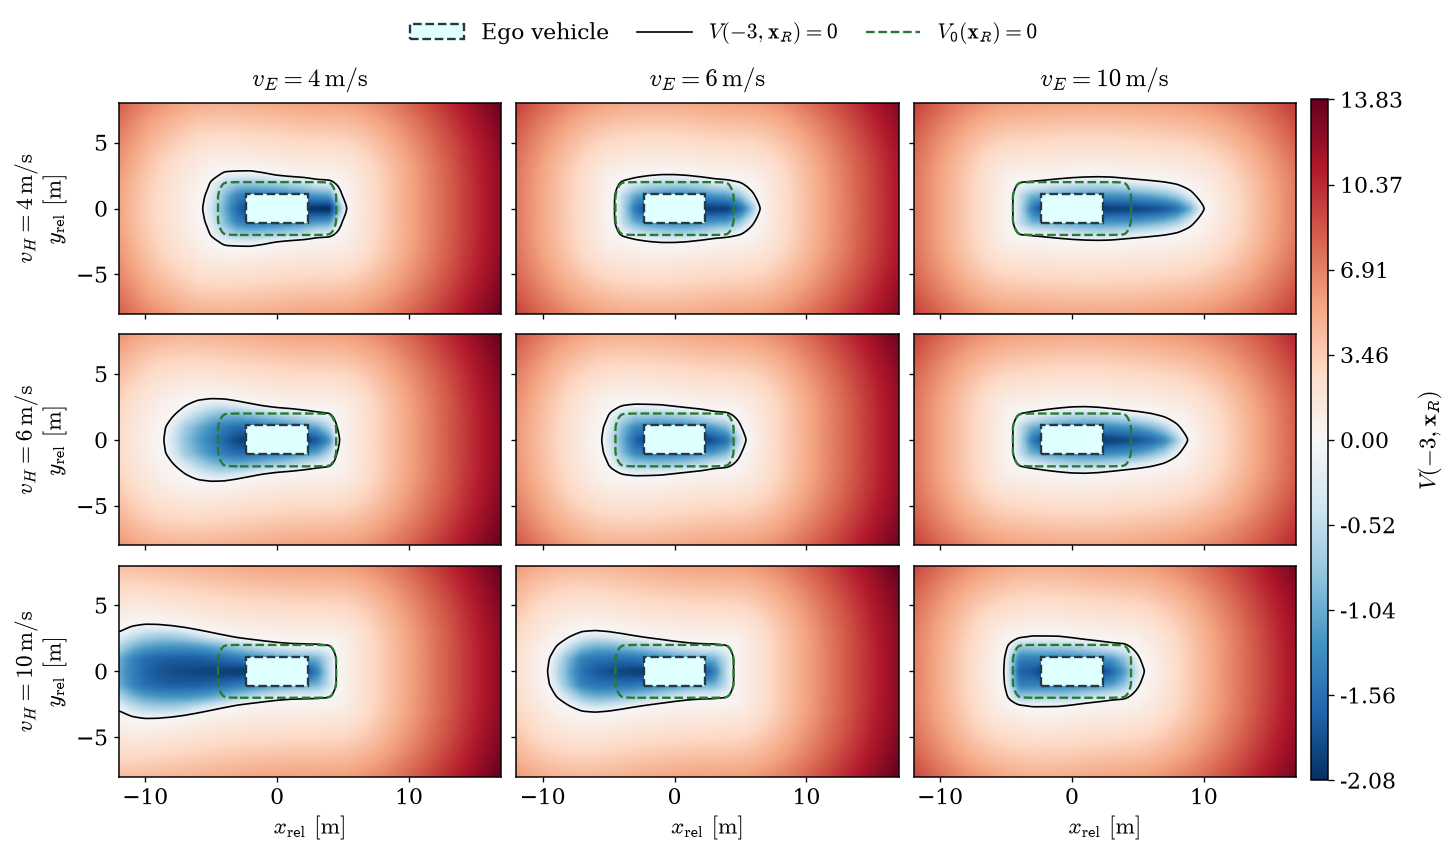

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt_slices.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very l

Salvato: /home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt_slices.eps


[PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt_slices.pdf'),
 PosixPath('/home/alessio-grisorio/TESI/hj_reachability/grafici/output/euclidean/euclidean_brt_slices.eps')]

In [12]:
METRIC = "euclidean"
DATA_DIRECTORY = ROOT / "results" / "brt"

V_E_VALUES = (4.0, 6.0, 10.0)
V_H_VALUES = (4.0, 6.0, 10.0)

THETA_MOSAIC = 0.0
DELTA_MOSAIC = 0.0

fig_brt_slices = make_speed_mosaic("BRT")
finish_figure(plt.gcf())
plt.show()

export_figure(
    fig_brt_slices,
    nome="euclidean_brt_slices",
    cartella=METRIC,
    formati=("pdf", "eps"),
    sovrascrivi=True,
)